## Charger les images

In [40]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('data/fashion-mnist_train.csv')

## Affichage de l'image 1

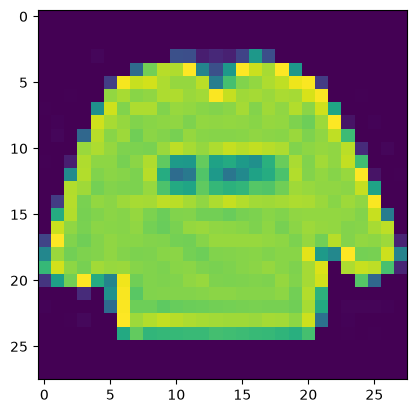

In [41]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage

In [42]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [43]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

## Préparation des données de tests

In [44]:
observations_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Une seule couche de convolution

In [45]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

#creation couche par couche
reseauNeurone1Convolution = Sequential()

#Ajout couche entrer
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#ajout couche comportant 32 filtres de taille 3x3
#fonction activation type ReLU
#image d'entrer de 28x28
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3,3),
                                     activation='relu'))

#def fonction de poolong avec une fenetre de 2x2
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2,2)))

#Ajout fonciton ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#transforme en 1 ligne
reseauNeurone1Convolution.add(Flatten())

#reseau neurone de 128n avec fonction ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#reseau neurone de 10n avec fonction softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax')) 

In [46]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [47]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8076 - loss: 0.5505 - val_accuracy: 0.8624 - val_loss: 0.3953
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8732 - loss: 0.3587 - val_accuracy: 0.8775 - val_loss: 0.3452
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8892 - loss: 0.3128 - val_accuracy: 0.8900 - val_loss: 0.3128
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8981 - loss: 0.2875 - val_accuracy: 0.8972 - val_loss: 0.2933
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9060 - loss: 0.2657 - val_accuracy: 0.9013 - val_loss: 0.2807
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9097 - loss: 0.2524 - val_accuracy: 0.9041 - val_loss: 0.2729
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9150 - loss: 0.2372 - val_accuracy: 0.9047 - val_loss: 0.2659
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9201 - loss: 0.2234 - val_accuracy: 0.

In [48]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.23677602410316467
Précision: 0.9156000018119812


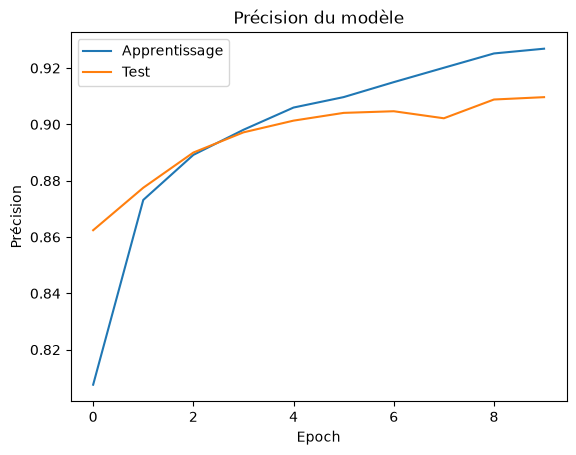

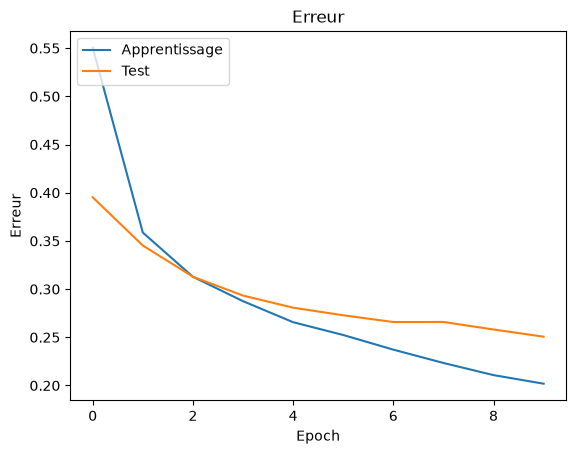

In [49]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()